# Simulasi Deep Neural Network (DNN) 2 Hidden Layers from Scratch
## Subkasus 2: Pemetaan Multi-Output $\mathbb{R}^3 \to \mathbb{R}^2$
### **Variasi 2 (Berdistribusi): Inisialisasi {M=1, Sigma=1, b=1}, Aktivasi ReLU**

Dokumen ini memuat implementasi *from scratch* komputasi matriks *forward pass* ($H^{(\ell)} = X^{(\ell-1)} W^{(\ell)} + \mathbf{1}_N \mathbf{b}^{(\ell)}$, $X^{(\ell)} = f(H^{(\ell)})$), evaluasi MSE *loss*, dan *backward pass* dengan konfigurasi berikut:

* **Sifat Bobot**: **Distribusi** (Reparameterization Trick: $W^{(\ell)} = M^{(\ell)} + \Sigma^{(\ell)} \odot Z^{(\ell)}$ dengan $Z^{(\ell)} \sim \mathcal{N}(0, I)$ matriks variabel acak normal baku)
* **Input Layer ($\ell = 0$)**: $n_0 = 3$ fitur
* **Hidden Layer 1 ($\ell = 1$)**: $n_1 = 4$ neuron, aktivasi ReLU
* **Hidden Layer 2 ($\ell = 2$)**: $n_2 = 6$ neuron, aktivasi ReLU
* **Output Layer ($\ell = 3$)**: $n_3 = 2$ neuron, aktivasi Linier
* **Banyak Data ($N$)**: $5$ sampel
* **Learning Rate ($\eta$)**: $0.5$
* **Total Iterasi**: $500$ iterasi
* **Random Seed**: $67$
* **Inisialisasi**: Semua parameter bernilai 1


In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True, linewidth=120)

# 1. Kunci Random Seed
np.random.seed(67)

# 2. Matriks Data Input X in R^(5 x 3)
X = np.array([
    [0.1, 0.2, 0.3],
    [0.4, 0.1, 0.5],
    [0.2, 0.6, 0.1],
    [0.5, 0.3, 0.2],
    [0.3, 0.4, 0.4]
], dtype=np.float64)

# 3. Target Pemetaan Multi-Output R^3 -> R^2:
# y1 = 0.5*x1 - 0.3*x2 + 0.8*x3
# y2 = -0.4*x1 + 0.7*x2 + 0.2*x3
y1 = 0.5 * X[:, 0] - 0.3 * X[:, 1] + 0.8 * X[:, 2]
y2 = -0.4 * X[:, 0] + 0.7 * X[:, 1] + 0.2 * X[:, 2]
Y = np.column_stack([y1, y2])
N = X.shape[0]

# 4. Dimensi Jaringan (Output Layer n3 = 2)
n0, n1, n2, n3 = 3, 4, 6, 2
lr = 0.5
num_epochs = 500

# 5. Fungsi Aktivasi Hidden Layer f(h) & Turunannya f'(h)
def activation(h):
    return np.maximum(0.0, h)

def activation_deriv(h):
    return (h > 0.0).astype(np.float64)

# 6. Inisialisasi Parameter Bobot dan Bias
# Matriks Rata-rata M, Simpangan Baku Sigma, dan Bias b bernilai 1 semua
M1 = np.ones((n0, n1), dtype=np.float64)
Sigma1 = np.ones((n0, n1), dtype=np.float64)
b1 = np.ones((1, n1), dtype=np.float64)

M2 = np.ones((n1, n2), dtype=np.float64)
Sigma2 = np.ones((n1, n2), dtype=np.float64)
b2 = np.ones((1, n2), dtype=np.float64)

M3 = np.ones((n2, n3), dtype=np.float64)
Sigma3 = np.ones((n2, n3), dtype=np.float64)
b3 = np.ones((1, n3), dtype=np.float64)
print("Data Input X (5 x 3):\n", X)
print("\nData Target Multi-Output Y (5 x 2):\n", Y)


Data Input X (5 x 3):
 [[0.1 0.2 0.3]
 [0.4 0.1 0.5]
 [0.2 0.6 0.1]
 [0.5 0.3 0.2]
 [0.3 0.4 0.4]]

Data Target Multi-Output Y (5 x 2):
 [[0.23 0.16]
 [0.57 0.01]
 [0.   0.36]
 [0.32 0.05]
 [0.35 0.24]]


In [2]:
# Loop Pelatihan (500 Iterasi)
history = []
milestones = [1, 2, 50, 100, 150, 200, 250, 300, 350, 400, 450, 500]
predictions_history = {}

for epoch in range(1, num_epochs + 1):
    # --- REPARAMETERIZATION TRICK & FORWARD PASS (BERDISTRIBUSI) ---
    # Z^(l) ~ N(0, I) adalah matriks variabel acak normal baku
    Z1 = np.random.randn(n0, n1)
    W1 = M1 + Sigma1 * Z1
    H1 = X @ W1 + b1
    X1 = activation(H1)
    
    Z2 = np.random.randn(n1, n2)
    W2 = M2 + Sigma2 * Z2
    H2 = X1 @ W2 + b2
    X2 = activation(H2)
    
    Z3 = np.random.randn(n2, n3)
    W3 = M3 + Sigma3 * Z3
    H3 = X2 @ W3 + b3
    Y_hat = H3
    
    # Evaluasi Loss: MSE Multi-Output = 1/(2N) * sum_{i, k} (Y_{i,k} - Y_hat_{i,k})^2
    loss = (0.5 / N) * np.sum((Y - Y_hat) ** 2)
    history.append((epoch, loss, Y_hat.copy()))
    if epoch in milestones:
        predictions_history[epoch] = Y_hat.copy()
        
    # --- BACKWARD PASS (BERDISTRIBUSI) ---
    # Layer 3 (l = 3)
    dL_dH3 = (1.0 / N) * (Y_hat - Y)             # (N x 2)
    dL_dW3 = X2.T @ dL_dH3                       # (6 x 2)
    dL_db3 = np.ones((1, N)) @ dL_dH3            # (1 x 2)
    dL_dM3 = dL_dW3
    dL_dSigma3 = dL_dW3 * Z3
    
    # Layer 2 (l = 2, menggunakan dL_dH3 dan W3 dari layer l+1 = 3)
    dL_dX2 = dL_dH3 @ W3.T                       # (N x 6)
    dL_dH2 = dL_dX2 * activation_deriv(H2)       # (N x 6)
    dL_dW2 = X1.T @ dL_dH2                       # (4 x 6)
    dL_db2 = np.ones((1, N)) @ dL_dH2            # (1 x 6)
    dL_dM2 = dL_dW2
    dL_dSigma2 = dL_dW2 * Z2
    
    # Layer 1 (l = 1, menggunakan dL_dH2 dan W2 dari layer l+1 = 2)
    dL_dX1 = dL_dH2 @ W2.T                       # (N x 4)
    dL_dH1 = dL_dX1 * activation_deriv(H1)       # (N x 4)
    dL_dW1 = X.T @ dL_dH1                        # (3 x 4)
    dL_db1 = np.ones((1, N)) @ dL_dH1            # (1 x 4)
    dL_dM1 = dL_dW1
    dL_dSigma1 = dL_dW1 * Z1
    
    # --- UPDATE PARAMETER DISTRIBUSI & BIAS ---
    M3 -= lr * dL_dM3
    Sigma3 -= lr * dL_dSigma3
    b3 -= lr * dL_db3
    
    M2 -= lr * dL_dM2
    Sigma2 -= lr * dL_dSigma2
    b2 -= lr * dL_db2
    
    M1 -= lr * dL_dM1
    Sigma1 -= lr * dL_dSigma1
    b1 -= lr * dL_db1

# Tampilkan Rangkuman Nilai Tiap Kelipatan 50 Iterasi
print(f"{'Iterasi':<8} | {'MSE Loss':<12} | {'Mean Y_hat (y1, y2)':<25} | {'Loss Relatif':<12}")
print("-" * 65)
for ep in milestones:
    _, ep_loss, ep_pred = history[ep - 1]
    mean_y1 = np.mean(ep_pred[:, 0])
    mean_y2 = np.mean(ep_pred[:, 1])
    print(f"{ep:<8} | {ep_loss:<12.6f} | ({mean_y1:.4f}, {mean_y2:.4f}) {'':<10} | {ep_loss / history[0][1]:<12.6f}")


Iterasi  | MSE Loss     | Mean Y_hat (y1, y2)       | Loss Relatif
-----------------------------------------------------------------
1        | 678.414583   | (28.2787, 23.8814)            | 1.000000    
2        | 5053449.035663 | (-3087.8697, -754.9140)            | 7448.909805 
50       | 0.025144     | (0.2940, 0.1640)            | 0.000037    
100      | 0.025144     | (0.2940, 0.1640)            | 0.000037    
150      | 0.025144     | (0.2940, 0.1640)            | 0.000037    
200      | 0.025144     | (0.2940, 0.1640)            | 0.000037    
250      | 0.025144     | (0.2940, 0.1640)            | 0.000037    
300      | 0.025144     | (0.2940, 0.1640)            | 0.000037    
350      | 0.025144     | (0.2940, 0.1640)            | 0.000037    
400      | 0.025144     | (0.2940, 0.1640)            | 0.000037    
450      | 0.025144     | (0.2940, 0.1640)            | 0.000037    
500      | 0.025144     | (0.2940, 0.1640)            | 0.000037    


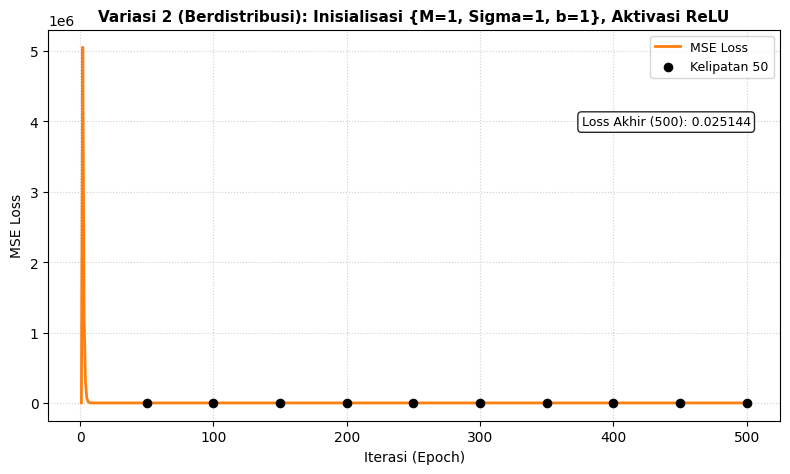

In [3]:
# Visualisasi Grafik Fungsi Loss (MSE Loss vs Iterasi 1 - 500)
epochs = np.array([h[0] for h in history])
losses = np.array([h[1] for h in history])

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(epochs, losses, color='#ff7f0e', linewidth=2, label='MSE Loss')
milestone_epochs = [50, 100, 150, 200, 250, 300, 350, 400, 450, 500]
milestone_losses = [losses[ep - 1] for ep in milestone_epochs]
ax.scatter(milestone_epochs, milestone_losses, color='black', s=35, zorder=5, label='Kelipatan 50')

ax.set_title("Variasi 2 (Berdistribusi): Inisialisasi {M=1, Sigma=1, b=1}, Aktivasi ReLU", fontsize=11, fontweight='bold')
ax.set_xlabel('Iterasi (Epoch)', fontsize=10)
ax.set_ylabel('MSE Loss', fontsize=10)
ax.grid(True, linestyle=':', alpha=0.6)
ax.legend(fontsize=9, loc='upper right')
ax.text(0.96, 0.78, f'Loss Akhir (500): {losses[-1]:.6f}', transform=ax.transAxes,
        fontsize=9, ha='right', va='top', bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.85))

plt.tight_layout()
plt.show()
